In [ ]:
import os
import glob
import pandas as pd
import numpy as np

from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D

%matplotlib inline

In [2]:

patron_archivos = "datasets/*.csv"
lista_archivos = sorted(glob.glob(patron_archivos))

df_lista = [pd.read_csv(archivo) for archivo in lista_archivos]
df_unificado = pd.concat(df_lista, ignore_index=True)

X = df_unificado.iloc[:, :10].values
y = df_unificado["NOX"].values

m = df_unificado.shape[0]
print(f"Total de filas y columnas del conjunto unificado: {m}")

print(("{:>12s}" * 11).format(
    'X[:,0]', 'X[:,1]', 'X[:,2]', 'X[:,3]', 'X[:,4]', 'X[:,5]', 'X[:,6]', 'X[:,7]', 'X[:,8]', 'X[:,9]', 'y (NOX)'
))
print('-' * 132)

for i in range(10):
    print(("{:12.2f}" * 11).format(X[i, 0], X[i, 1], X[i, 2], X[i, 3], X[i, 4],X[i, 5], X[i, 6], X[i, 7], X[i, 8], X[i, 9], y[i]))

Total de filas y columnas del conjunto unificado: 36733
      X[:,0]      X[:,1]      X[:,2]      X[:,3]      X[:,4]      X[:,5]      X[:,6]      X[:,7]      X[:,8]      X[:,9]     y (NOX)
------------------------------------------------------------------------------------------------------------------------------------
        4.59     1018.70       83.67        3.58       23.98     1086.20      549.83      134.67       11.90        0.33       81.95
        4.29     1018.30       84.23        3.57       23.95     1086.10      550.05      134.67       11.89        0.45       82.38
        3.90     1018.40       84.86        3.58       23.99     1086.50      550.19      135.10       12.04        0.45       83.78
        3.74     1018.30       85.43        3.58       23.91     1086.50      550.17      135.03       11.99        0.23       82.50
        3.75     1017.80       85.18        3.58       23.92     1085.90      550.00      134.67       11.91        0.27       82.03
        3.89 

In [3]:
def featureNormalize(X):
    
    X_norm = X.copy()
    mu = np.zeros(X.shape[1])
    sigma = np.zeros(X.shape[1])

    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    
    X_norm = (X - mu) / sigma

    return X_norm, mu, sigma

X_norm, mu, sigma = featureNormalize(X)

print("Primeras 3 características del primer ejemplo (Original):")
print(X[0, :3])

print("\nPrimeras 3 características del primer ejemplo (Normalizado):")
print(X_norm[0, :3])

Primeras 3 características del primer ejemplo (Original):
[   4.5878 1018.7      83.675 ]

Primeras 3 características del primer ejemplo (Normalizado):
[-1.76236198  0.87105219  0.40162651]


In [4]:
X = np.concatenate([np.ones((m, 1)), X_norm], axis=1)

print(f"Dimensiones de X antes: {X_norm.shape}")
print(f"Dimensiones de X ahora (con x0): {X.shape}")

print("\nPrimeras 3 filas y primeras 4 columnas de X:")
print(X[:3, :4])

Dimensiones de X antes: (36733, 10)
Dimensiones de X ahora (con x0): (36733, 11)

Primeras 3 filas y primeras 4 columnas de X:
[[ 1.         -1.76236198  0.87105219  0.40162651]
 [ 1.         -1.80191968  0.8091639   0.44035094]
 [ 1.         -1.85411274  0.82463597  0.48343186]]


In [ ]:
def computeCostMulti(X, y, theta):

    m = y.shape[0]
    
    J = 0
    
    J = (1 / (2 * m)) * np.sum(np.square(np.dot(X, theta) - y))
    
    return J


theta_inicial = np.zeros(X.shape[1])


costo_inicial = computeCostMulti(X, y, theta_inicial)

print(f"Número de muestras (m): {y.shape[0]}")
print(f"Dimensiones de theta: {theta_inicial.shape}")
print(f"Costo inicial (con theta = 0): {costo_inicial:.4f}")

NameError: name 'np' is not defined

In [6]:
def gradientDescentMulti(X, y, theta, alpha, num_iters):
  
    m = y.shape[0]
    theta = theta.copy()
    J_history = []

    for i in range(num_iters):
        
        predictions = np.dot(X, theta)
        errors = predictions - y
        theta = theta - (alpha / m) * np.dot(X.T, errors)
        J_history.append(computeCostMulti(X, y, theta))

    return theta, J_history

theta calculado por el descenso por el gradiente: [ 65.29306727 -10.03204194  -1.32026706  -2.97504114   1.02335267
  -5.50181522  19.53782734  -7.34955001  -9.93003311  -8.41116892
   4.17296098]


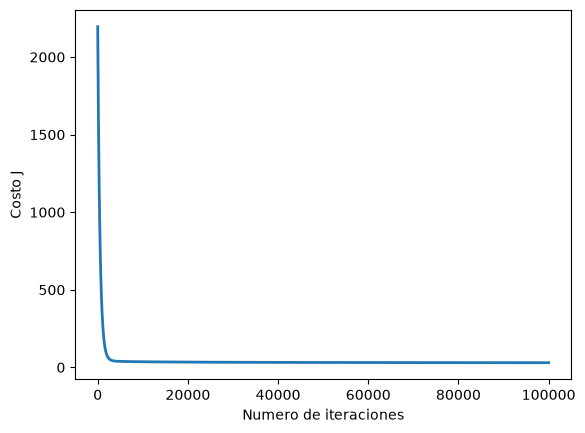

In [7]:
alpha = 0.001
num_iters = 100000

theta = np.zeros(X.shape[1])

theta, J_history = gradientDescentMulti(X, y, theta, alpha, num_iters)

pyplot.plot(np.arange(len(J_history)), J_history, lw=2)
pyplot.xlabel('Numero de iteraciones')
pyplot.ylabel('Costo J')

print('theta calculado por el descenso por el gradiente: {:s}'.format(str(theta)))

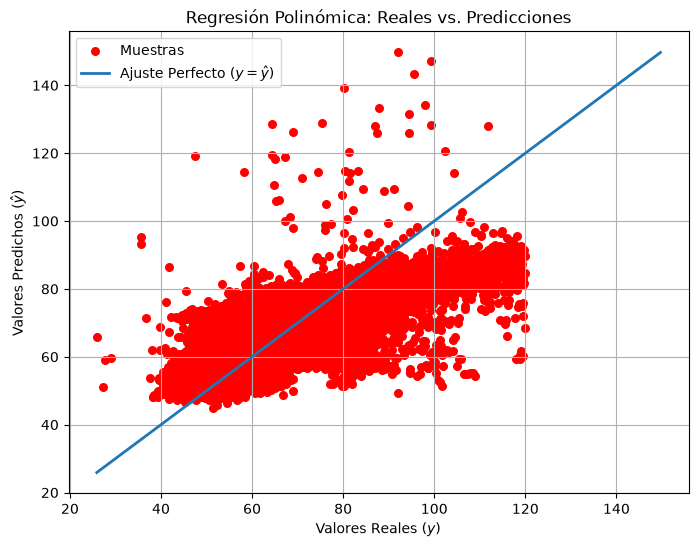

In [8]:
y_pred = np.dot(X, theta)

y_real = y.flatten()
y_pred = y_pred.flatten()

# 2. Graficar Reales vs Predichos
pyplot.figure(figsize=(8, 6))
pyplot.scatter(y_real, y_pred, color='red', s=30, label='Muestras')

# Línea de referencia y = x (predicción perfecta)
lim_min = min(y_real.min(), y_pred.min())
lim_max = max(y_real.max(), y_pred.max())
pyplot.plot([lim_min, lim_max], [lim_min, lim_max], '-', lw=2, label='Ajuste Perfecto ($y = \hat{y}$)')

pyplot.xlabel('Valores Reales ($y$)')
pyplot.ylabel('Valores Predichos ($\hat{y}$)')
pyplot.title('Regresión Polinómica: Reales vs. Predicciones')
pyplot.legend()
pyplot.grid(True)
pyplot.show()